# **🏠 House Sales Price Study**

---

## 📋 1. Summary

## Objectives
Answer business requirement 1:
* The client is interested in discovering how house attributes correlate with sale prices. 
* Therefore, the client expects data visualizations of the correlated variables against the `SalePrice`.

## Inputs

- `outputs/datasets/cleaned/TrainSetCleaned.csv`
- `outputs/datasets/cleaned/TestSetCleaned.csv`

## Outputs

- Generate analysis and visualisations that can be used to support the Heritage Housing dashboard.

## Additional Comments

This notebook forms part of the **Data Understanding** stage of the CRISP-DM process.

---

## ⚙️ 2. Set Up the Notebook

### Change working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'/workspaces/milestone-project5-heritage-housing-issues/jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chdir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'/workspaces/milestone-project5-heritage-housing-issues'

---

## 📥 3. Load Data

Import heritage housing historical data that has been cleaned in the previous notebook.

In [4]:
import pandas as pd

TrainSet = pd.read_csv(
    "outputs/datasets/cleaned/TrainSetCleaned.csv"
)

TestSet = pd.read_csv(
    "outputs/datasets/cleaned/TestSetCleaned.csv"
)

df = pd.concat([TrainSet, TestSet], ignore_index=True)

print(f"Dataset shape: {df.shape}")
df.head(3)

Dataset shape: (1460, 22)


,1stFlrSF,2ndFlrSF,BedroomAbvGr,BsmtExposure,BsmtFinSF1,BsmtFinType1,BsmtUnfSF,GarageArea,GarageFinish,GarageYrBlt,...,LotArea,LotFrontage,MasVnrArea,OpenPorchSF,OverallCond,OverallQual,TotalBsmtSF,YearBuilt,YearRemodAdd,SalePrice
0,1828,0.0,3.0,Av,48,Missing,1774,774,Unf,2007.0,...,11694,90.0,452.0,108,5,9,1822,2007,2007,314813
1,894,0.0,2.0,No,0,Unf,894,308,Missing,1962.0,...,6600,60.0,0.0,0,5,5,894,1962,1962,109500
2,964,0.0,2.0,No,713,ALQ,163,432,Unf,1921.0,...,13360,80.0,0.0,0,7,5,876,1921,2006,163500


---

## 🔍 4. Data Exploration

### 4.1 Pandas Profiling Report
I will inspect the dataset to understand the variable types, distributions, and relationships between property features and `SalePrice`.

In [5]:
from ydata_profiling import ProfileReport

pandas_report = ProfileReport(df=df, minimal=True)
pandas_report.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

 ## 📊 5. Correlation Study

* To calculate correlations between all variables and `SalePrice`, categorical variables first need to be converted into numerical form.
* This is done using `OneHotEncoder`.

In [6]:
from feature_engine.encoding import OneHotEncoder

categorical_cols = df.select_dtypes(include='object').columns.to_list()

encoder = OneHotEncoder(
    variables=categorical_cols,
    drop_last=False
)

df_ohe = encoder.fit_transform(df)

print(df_ohe.shape)
df_ohe.head(3)

(1460, 41)


,1stFlrSF,2ndFlrSF,BedroomAbvGr,BsmtFinSF1,BsmtUnfSF,GarageArea,GarageYrBlt,GrLivArea,LotArea,LotFrontage,...,BsmtFinType1_BLQ,GarageFinish_Unf,GarageFinish_Missing,GarageFinish_RFn,GarageFinish_Fin,GarageFinish_No Garage,KitchenQual_Gd,KitchenQual_TA,KitchenQual_Ex,KitchenQual_Fa
0,1828,0.0,3.0,48,1774,774,2007.0,1828,11694,90.0,...,0,1,0,0,0,0,1,0,0,0
1,894,0.0,2.0,0,894,308,1962.0,894,6600,60.0,...,0,0,1,0,0,0,0,1,0,0
2,964,0.0,2.0,713,163,432,1921.0,964,13360,80.0,...,0,1,0,0,0,0,0,1,0,0


The four categorical variables were replaced by **23 one-hot encoded columns**:

- `BsmtExposure` → `No`, `Gd`, `Mn`, `Av`, `No Basement`, `Missing`
- `BsmtFinType1` → `GLQ`, `ALQ`, `Unf`, `Rec`, `Missing`, `BLQ`, `No Basement`, `LwQ`
- `GarageFinish` → `RFn`, `Unf`, `Missing`, `Fin`, `No Garage`
- `KitchenQual` → `Gd`, `TA`, `Ex`, `Fa`

This increased the dataset from **22 to 41 columns**. (22 - 4 + 23 = 41)

### 5.1 Spearman Correlation

Spearman correlation will be used to measure the strength and direction of the relationship between each encoded variable and `SalePrice`.

The absolute correlation values will be sorted to identify the variables most strongly associated with `SalePrice`.

In [7]:
corr_spearman = df_ohe.corr(method='spearman')['SalePrice'].sort_values(key=abs, ascending=False)[1:].head(10)
corr_spearman

OverallQual       0.809829
GrLivArea         0.731310
YearBuilt         0.652682
GarageArea        0.649379
GarageYrBlt       0.634095
TotalBsmtSF       0.602725
KitchenQual_TA   -0.581803
1stFlrSF          0.575408
YearRemodAdd      0.571159
KitchenQual_Gd    0.478583
Name: SalePrice, dtype: float64

### 5.2 Pearson Correlation

Pearson correlation will also be calculated to measure the linear relationship between each encoded variable and `SalePrice`.

The strongest relationships can then be compared with those identified by the Spearman correlation.

In [8]:
corr_pearson = df_ohe.corr(method='pearson')['SalePrice'].sort_values(key=abs, ascending=False)[1:].head(10)
corr_pearson

OverallQual       0.790982
GrLivArea         0.708624
GarageArea        0.623431
TotalBsmtSF       0.613581
1stFlrSF          0.605852
YearBuilt         0.522897
KitchenQual_TA   -0.519298
YearRemodAdd      0.507101
KitchenQual_Ex    0.504094
MasVnrArea        0.472614
Name: SalePrice, dtype: float64

In [9]:
top_n = 5
set(corr_pearson[:top_n].index.to_list() + corr_spearman[:top_n].index.to_list())

{'1stFlrSF',
 'GarageArea',
 'GarageYrBlt',
 'GrLivArea',
 'OverallQual',
 'TotalBsmtSF',
 'YearBuilt'}

- The five strongest correlations from each method were combined. 
- Since some variables appear in both lists, this resulted in **seven** unique variables being selected for further analysis.

### 5.3 Correlation Study Interpretation

We can conclude from the above results that the following variables are associated with a higher sale price:

- Higher overall property quality (`OverallQual`)
- Larger living areas (`GrLivArea`)
- Larger garages (`GarageArea`)
- Properties with newer garages (`GarageYrBlt`)
- Larger basement areas (`TotalBsmtSF`)
- Larger first-floor areas (`1stFlrSF`)
- Newer properties (`YearBuilt`)

Kitchen quality also shows a relationship with `SalePrice`. Typical/Average kitchens (`KitchenQual_TA`) are associated with lower sale prices, while Excellent kitchens (`KitchenQual_Ex`) are associated with higher sale prices.

Based on these results, the following variables will be investigated further through visual analysis.

In [10]:
vars_to_study = [
    'OverallQual',
    'GrLivArea',
    'GarageArea',
    'GarageYrBlt',
    'TotalBsmtSF',
    '1stFlrSF',
    'YearBuilt'
]

vars_to_study

['OverallQual',
 'GrLivArea',
 'GarageArea',
 'GarageYrBlt',
 'TotalBsmtSF',
 '1stFlrSF',
 'YearBuilt']

In [11]:
df_eda = df.filter(vars_to_study + ['SalePrice'])

df_eda.head(3)

,OverallQual,GrLivArea,GarageArea,GarageYrBlt,TotalBsmtSF,1stFlrSF,YearBuilt,SalePrice
0,9,1828,774,2007.0,1822,1828,2007,314813
1,5,894,308,1962.0,894,894,1962,109500
2,5,964,432,1921.0,876,964,1921,163500


## 📈 6. EDA on Selected Variables

The variables identified in the correlation study will now be investigated further through visual analysis.

### 6.1 Variables vs Sale Price

- The selected variables will be plotted against `SalePrice` to examine their relationships and identify any unusual observations.
- For `GarageArea`, `GarageYrBlt` and `TotalBsmtSF`, zero values are excluded from the scatterplots to make the relationships with SalePrice easier to visualise.

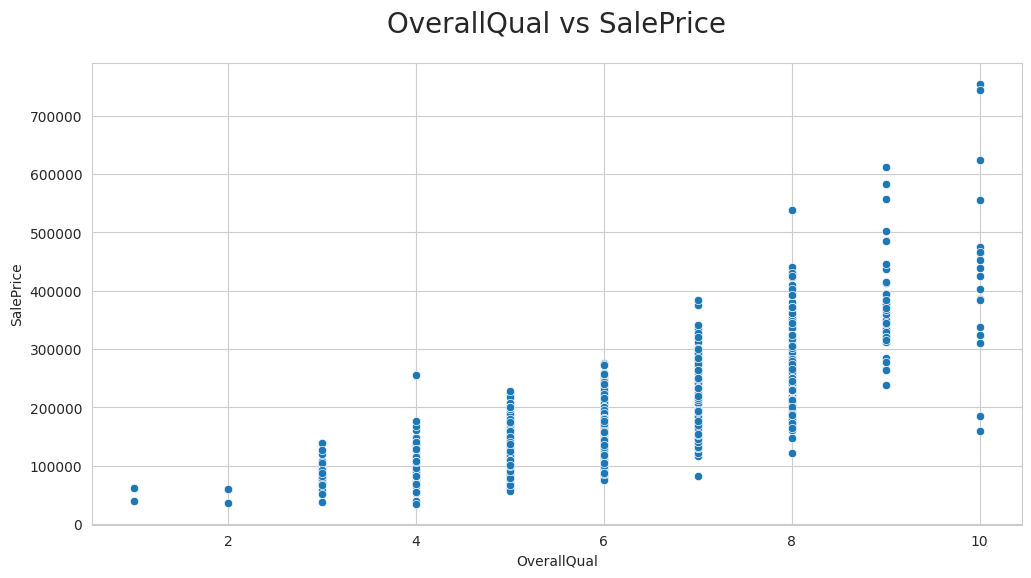

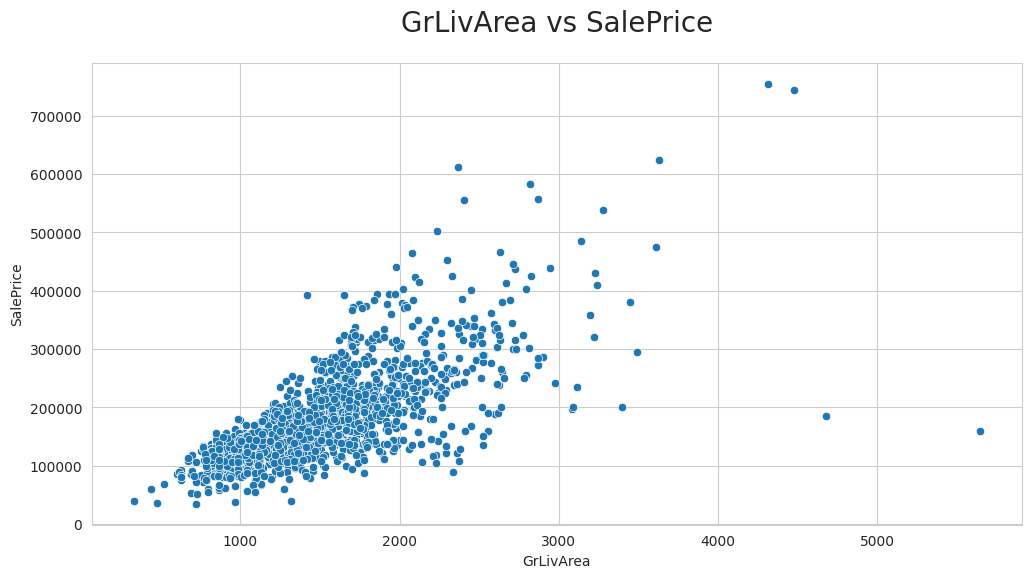

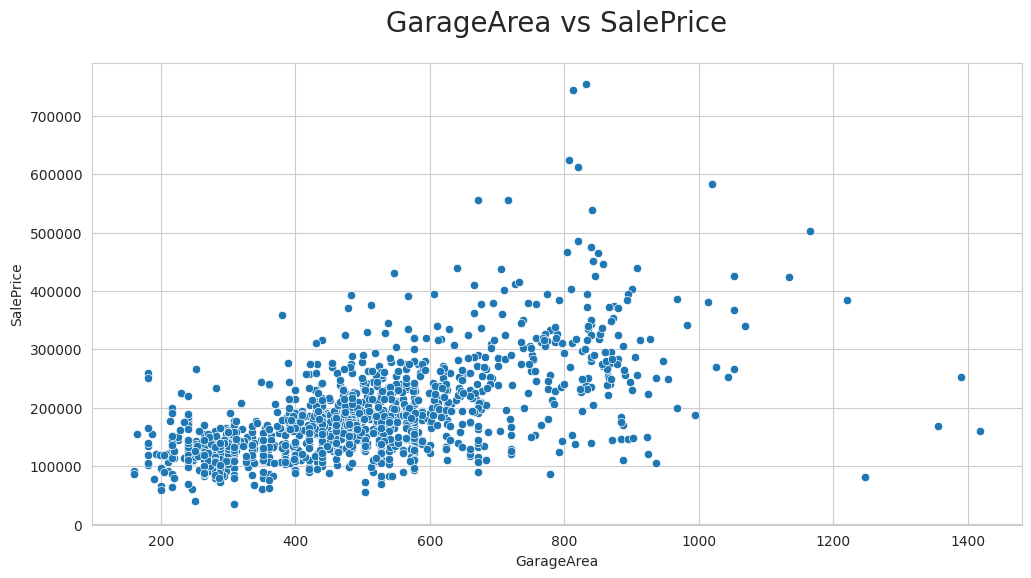

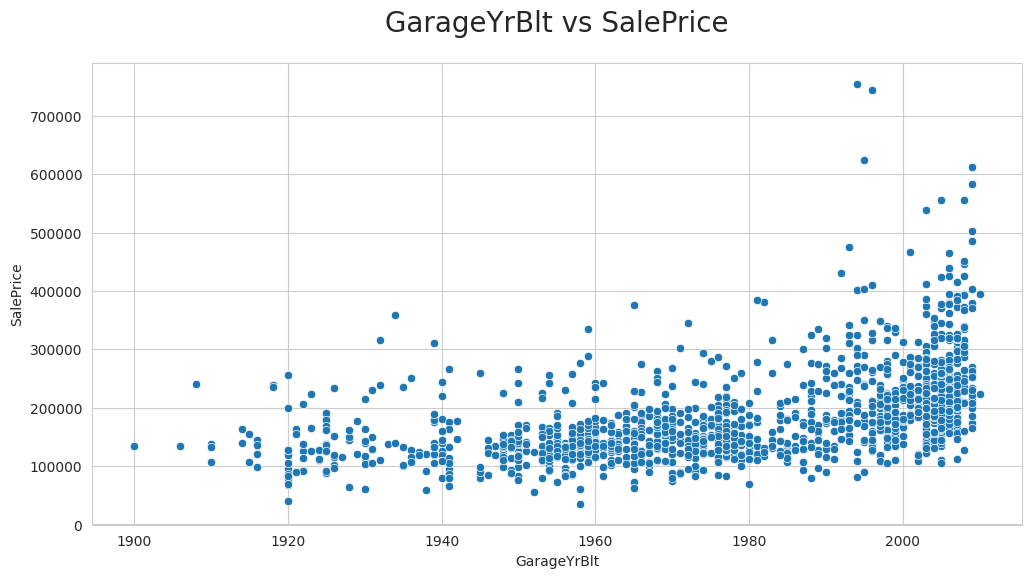

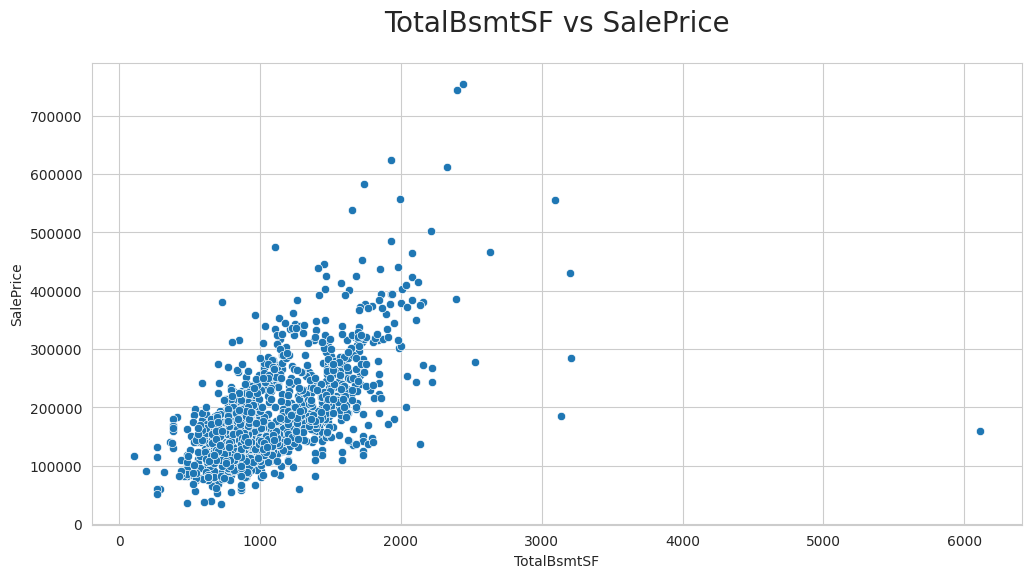

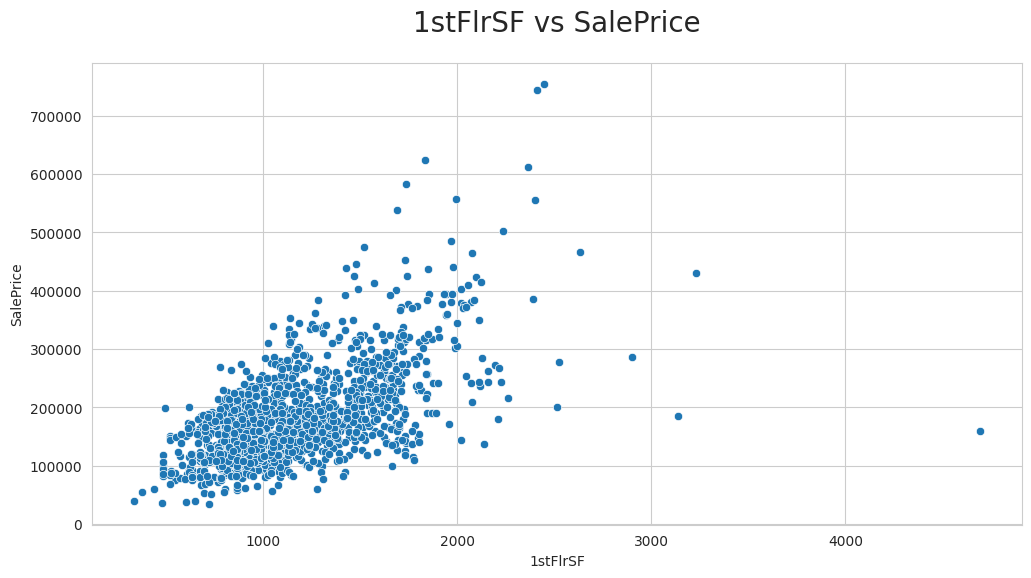

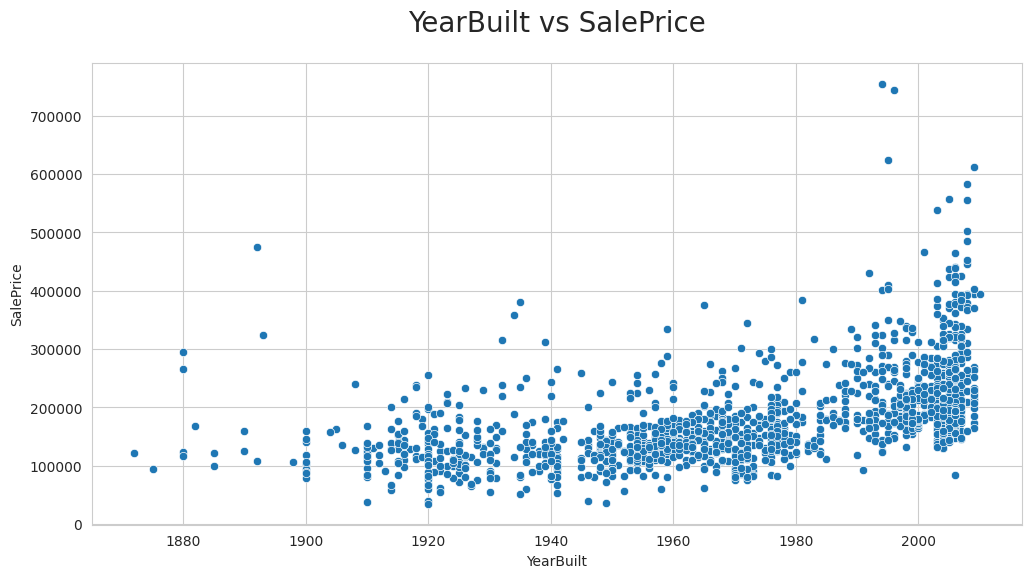

In [12]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

sns.set_style('whitegrid')


def scatter_plot_for_eda(df, col, target_var):
    # Exclude zero values from selected scatter plots
    if col in ['GarageArea', 'GarageYrBlt', 'TotalBsmtSF']:
        df = df[df[col] > 0]

    plt.figure(figsize=(12, 6))
    sns.scatterplot(data=df, x=col, y=target_var)
    plt.title(f"{col} vs {target_var}", fontsize=20, y=1.05)
    plt.show()


def variables_plots(df_eda):
    target_var = 'SalePrice'

    for col in df_eda.drop([target_var], axis=1).columns.to_list():
        scatter_plot_for_eda(df_eda, col, target_var)


variables_plots(df_eda)

### 6.2 Correlation Heatmaps

Pearson and Spearman correlation heatmaps will be used to provide an overview of the relationships between the selected variables and `SalePrice`. This code has been taken from the Code Institute tutorial entitled Predictive Power Score Unit 1: Introduction.

In [13]:
df_corr_spearman = df_eda.corr(method='spearman')
df_corr_pearson = df_eda.corr(method='pearson')

In [14]:
import numpy as np


def heatmap_corr(df, threshold, figsize=(20, 12), font_annot=8):
    if len(df.columns) > 1:
        mask = np.zeros_like(df, dtype=bool)
        mask[np.triu_indices_from(mask)] = True
        mask[abs(df) < threshold] = True

        fig, axes = plt.subplots(figsize=figsize)

        sns.heatmap(
            df,
            annot=True,
            xticklabels=True,
            yticklabels=True,
            mask=mask,
            cmap='viridis',
            annot_kws={"size": font_annot},
            ax=axes,
            linewidth=0.5
        )

        axes.set_yticklabels(df.columns, rotation=0)
        plt.ylim(len(df.columns), 0)
        plt.show()

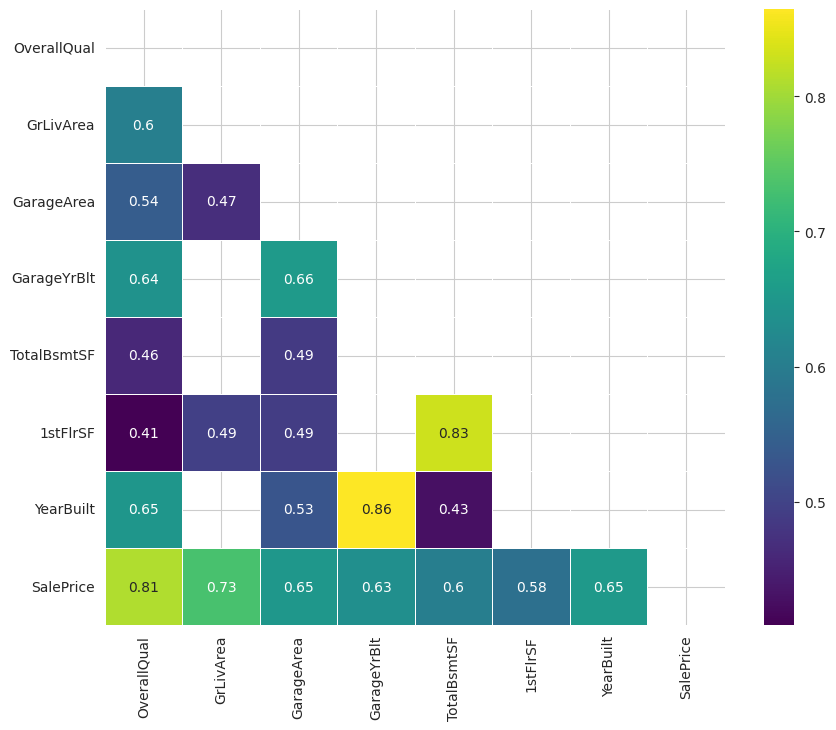

In [15]:
heatmap_corr(
    df=df_corr_spearman,
    threshold=0.4,
    figsize=(10, 8),
    font_annot=10
)

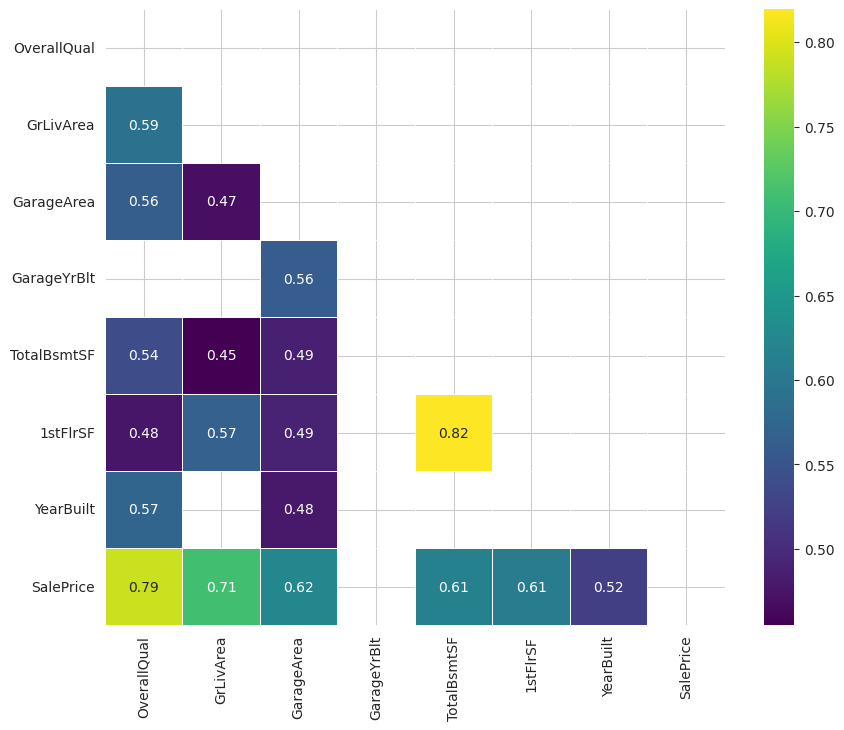

In [16]:
heatmap_corr(
    df=df_corr_pearson,
    threshold=0.4,
    figsize=(10, 8),
    font_annot=10
)

### 6.3 EDA Interpretation

The scatter plots and heatmaps support the findings from the correlation study.

The heatmaps also show strong correlations between `YearBuilt` and `GarageYrBlt`, and between `TotalBsmtSF` and `1stFlrSF`.

The scatter plots highlight some outliers in the dataset:

- `GrLivArea` contains a couple of very large properties with relatively low `SalePrice`.
- `GarageArea` contains a small number of properties with very large garages and relatively low `SalePrice`.
- `TotalBsmtSF` contains one property in particular with a very large basement and relatively low `SalePrice`.
- `GarageYrBlt`, `GarageArea`, and `TotalBsmtSF` contain zero values representing properties without a garage or basement, so these are not considered true outliers.

These findings will be kept in mind during the feature engineering and machine learning stages.

---

## ✅ 7. Conclusions

The Sale Price Study answered **Business Requirement 1** by identifying the property attributes most strongly associated with `SalePrice`.

- `OverallQual` and `GrLivArea` showed the strongest relationships with `SalePrice` across both Pearson and Spearman correlation methods.
- `GarageArea`, `GarageYrBlt`, `TotalBsmtSF`, `1stFlrSF`, and `YearBuilt` were also identified as important variables.
- The scatter plots identified a small number of outliers, which are to be expected.
- The heatmaps highlighted strong correlations between some of the property features, particularly `YearBuilt` and `GarageYrBlt`, and `TotalBsmtSF` and `1stFlrSF`.

We will keep these findings in mind during the feature engineering and machine learning stages.